In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
import joblib

In [9]:
data = Path('../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df = pd.read_csv(data)
print('(Rows, Columns) : ', df.shape)
print(df.info())


(Rows, Columns) :  (7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 

In [10]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df[df['TotalCharges'].isna()]


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [11]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)

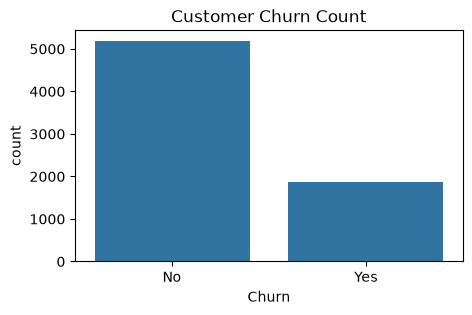

In [12]:
churn = df['Churn'].value_counts()
plt.figure(figsize=(5,3))
sns.countplot(x='Churn', data=df)
plt.title('Customer Churn Count')
plt.show()

## Does predicted probability line up with actual churn?

The next two cells check whether the model's predicted probabilities are trustworthy: do customers with higher predicted churn probability actually churn more often?

1. **Score the test set.** Load the saved model and the held-out test data, run `predict_proba` to get each customer's churn probability, and attach both the actual `Churn` label and the predicted `Churn_prob` to every row.
2. **Compare by probability range.** Bucket customers into the four risk bands used by the app (0-0.25, 0.25-0.5, 0.5-0.8, 0.8-1.0), then measure the share that actually churned in each band and plot actual churn counts per band.

In [13]:
X_test_encoded = joblib.load('../model/X_test.joblib')
X_test_preencode = joblib.load('../model/X_test_preencode.joblib')
y_test_preencode = joblib.load('../model/y_test_preencode.joblib')
model = joblib.load('../model/model.joblib')
prob = model.predict_proba(X_test_encoded)[:,1]
X_test_preencode['Churn'] = y_test_preencode
X_test_preencode['Churn_prob'] = prob
X_test_preencode

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_prob
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20,No,0.099946
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,No,0.789519
2235,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,...,No,Yes,No,One year,Yes,Credit card (automatic),78.35,3211.20,No,0.114233
4460,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,...,Yes,No,No,Month-to-month,No,Electronic check,78.20,1468.75,No,0.526578
3761,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,...,No,Yes,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35,No,0.067169
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5143,Female,0,Yes,Yes,49,Yes,No,DSL,Yes,Yes,...,Yes,Yes,Yes,One year,Yes,Mailed check,87.20,4345.00,No,0.135375
4439,Male,0,Yes,Yes,28,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,Two year,Yes,Credit card (automatic),20.30,487.95,No,0.034055
3857,Male,0,No,No,5,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,Month-to-month,No,Bank transfer (automatic),20.65,93.55,No,0.259328
4758,Female,0,No,No,56,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),19.70,1051.90,No,0.035443


Percentage of Actual churn in each Predicted Churn Probability:
(0.0, 0.25] percentage of actual churn is 4.82%
(0.25, 0.5] percentage of actual churn is 20.70%
(0.5, 0.8] percentage of actual churn is 50.63%
(0.8, 1.0] percentage of actual churn is 82.98%


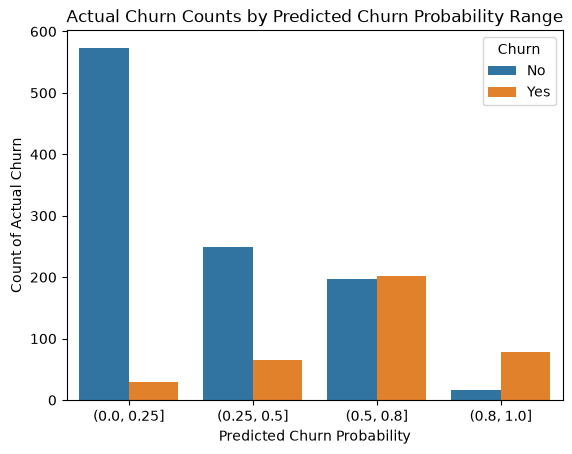

In [14]:
churnprob = X_test_preencode.groupby(pd.cut(X_test_preencode['Churn_prob'], bins=[0.0, 0.25, 0.5, 0.8, 1]))['Churn'].value_counts()
churnprob = churnprob.to_frame()
churnprob = churnprob.reset_index()
print('Percentage of Actual churn in each Predicted Churn Probability:')
churnprob['total'] = churnprob.groupby('Churn_prob')['count'].transform('sum')
churn = churnprob[churnprob['Churn']=='Yes']
for i in range(len(churn)):
    print(f'{list(churn["Churn_prob"])[i]}' \
          f' percentage of actual churn is {(list(churn["count"])[i]/list(churn["total"])[i])*100:.2f}%')

sns.barplot(data=churnprob, x='Churn_prob', y='count', hue='Churn')
plt.ylabel('Count of Actual Churn')
plt.xlabel('Predicted Churn Probability')
plt.title('Actual Churn Counts by Predicted Churn Probability Range')
plt.savefig('../assets/risk_analyze.png')
plt.show()

